In [1]:
# 导入库和设置环境
import torch
import torch.nn as nn
import pandas as pd
import numpy as np
import os
import json
from torch.utils.data import Dataset, DataLoader, random_split
import time
import matplotlib.pyplot as plt
from datetime import datetime
from torch.amp import GradScaler, autocast  # 修改为 torch.amp

# 环境配置
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 确认 PyTorch 和 CUDA 版本
print(f"PyTorch 版本: {torch.__version__}")
print(f"CUDA 可用: {torch.cuda.is_available()}")
print(f"CUDA 版本: {torch.version.cuda}")
print(f"设备: {device}")
print(f"GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else '无'}")

print("环境设置完成！")

PyTorch 版本: 2.3.0+cu121
CUDA 可用: True
CUDA 版本: 12.1
设备: cuda
GPU: NVIDIA GeForce RTX 4090
环境设置完成！


In [2]:
class TransformerModel(nn.Module):
    def __init__(self, num_groups, group_size, d_model, nhead, num_layers, output_dim_per_group, sequence_length, group=True, dropout_rate=0.1):
        super().__init__()
        self.num_groups = num_groups  # 组数（比如 20 或 1）
        self.group_size = group_size  # 每组特征数（比如 19 或 20）
        self.d_model = d_model
        self.group = group
        self.sequence_length = sequence_length
        self.output_dim_per_group = output_dim_per_group
        
        # 输入投影：将每组特征 (group_size) 映射到 d_model
        self.input_projection = nn.Linear(group_size, d_model)
        self.positional_encoding = nn.Parameter(torch.zeros(1, num_groups, d_model))
        self.transformer = nn.TransformerEncoder(
            nn.TransformerEncoderLayer(
                d_model=d_model, 
                nhead=nhead, 
                dropout=dropout_rate, 
                batch_first=True
            ),
            num_layers=num_layers
        )
        if self.group:
            # 分组时，每组输出 output_dim_per_group 个值
            self.fc = nn.Linear(d_model, output_dim_per_group)
        else:
            # 不分组时，直接输出 4 * sequence_length 个值
            self.fc = nn.Linear(d_model, output_dim_per_group * sequence_length)
        self.dropout = nn.Dropout(dropout_rate)
    
    def forward(self, x):
        x = self.input_projection(x)  # (batch_size, num_groups, d_model)
        x = x + self.positional_encoding  # 添加位置编码
        x = self.transformer(x)  # (batch_size, num_groups, d_model)
        x = self.dropout(x)
        x = self.fc(x)  # (batch_size, num_groups, output_dim)
        if self.group:
            # 分组时：(batch_size, num_groups, output_dim_per_group) -> (batch_size, output_dim_per_group, num_groups)
            return x.transpose(1, 2)  # 比如 (batch_size, 4, 20)
        else:
            # 不分组时：(batch_size, 1, output_dim_per_group * sequence_length) -> (batch_size, output_dim_per_group, sequence_length)
            return x.view(-1, self.output_dim_per_group, self.sequence_length)  # 比如 (batch_size, 4, 20)

# DNN 模型
class SignalDNN(nn.Module):
    def __init__(self, input_dim, hidden_dims, output_dim, dropout_rate, sequence_length):  # 添加 sequence_length 参数
        super().__init__()
        self.sequence_length = sequence_length
        layers = []
        prev_dim = input_dim
        for hidden_dim in hidden_dims:
            layers.extend([
                nn.Linear(prev_dim, hidden_dim),
                nn.ReLU(),
                nn.Dropout(dropout_rate)
            ])
            prev_dim = hidden_dim
        layers.append(nn.Linear(prev_dim, output_dim))
        self.network = nn.Sequential(*layers)
    
    def forward(self, x):
        x = self.network(x)
        return x.view(-1, 4, self.sequence_length)  # 动态调整为 sequence_length

class SignalDataset(Dataset):
    def __init__(self, detection_data, signal_data, num_features, sequence_length, final_gap, model_type="dnn", denoise=True, group=True):
        self.model_type = model_type
        self.num_features = num_features  # 总特征数（比如 390）
        self.sequence_length = sequence_length  # 序列长度（比如 20）
        self.final_gap = final_gap  # final_gap（比如 30）
        self.denoise = denoise
        self.group = group
        
        # 打印输入数据形状
        print(f"Input detection_data shape: {detection_data.shape}")
        
        # 根据 denoise 设置有效特征数
        if self.denoise:
            gap = final_gap // 2
            self.effective_features = num_features - 2 * gap  # 比如 390 - 2 * 15 = 360
            self.X = detection_data[:, gap:num_features - gap]  # 截取中间部分
        else:
            self.effective_features = num_features  # 比如 390
            self.X = detection_data
        
        print(f"After denoise, self.X shape: {self.X.shape}, effective_features: {self.effective_features}")
        
        # 检查 self.X 的列数是否匹配 effective_features
        actual_features = self.X.shape[1]
        if actual_features != self.effective_features:
            raise ValueError(f"Actual features ({actual_features}) do not match expected effective_features ({self.effective_features})")
        
        # 标准化并处理 NaN/Inf
        self.X = (self.X - self.X.mean()) / (self.X.std() + 1e-8)  # 避免除以 0
        self.X = torch.nan_to_num(self.X, nan=0.0, posinf=0.0, neginf=0.0)
        
        if self.model_type == "transformer":
            if self.group:
                # 动态调整 group_size（方法 3）
                group_size = self.effective_features // self.sequence_length  # 基本组大小，比如 390 // 20 = 19
                remainder = self.effective_features % self.sequence_length  # 剩余特征数，比如 390 % 20 = 10
                
                # 计算每组的特征数
                split_sizes = []
                for i in range(self.sequence_length):
                    if i < remainder:
                        split_sizes.append(group_size + 1)  # 前 remainder 组多分配 1 个特征
                    else:
                        split_sizes.append(group_size)
                
                # 确保总特征数匹配
                assert sum(split_sizes) == self.effective_features, f"Split sizes {sum(split_sizes)} do not match effective_features {self.effective_features}"
                
                # 按 split_sizes 分割 self.X
                split_tensors = torch.split(self.X, split_sizes, dim=1)
                
                # 统一组大小，填充 0
                max_group_size = max(split_sizes)  # 最大组大小，比如 20
                grouped_tensors = []
                for i, tensor in enumerate(split_tensors):
                    if split_sizes[i] < max_group_size:
                        padding = torch.zeros(tensor.shape[0], max_group_size - split_sizes[i], device=tensor.device)
                        tensor = torch.cat([tensor, padding], dim=1)
                    grouped_tensors.append(tensor)
                
                # 组合成 (batch_size, sequence_length, max_group_size)
                self.X = torch.stack(grouped_tensors, dim=1)
                print(f"Transformer grouped, self.X shape: {self.X.shape}, max_group_size: {max_group_size}")
            else:
                # 不分组：(batch_size, effective_features) -> (batch_size, 1, effective_features)
                self.X = self.X.view(-1, 1, self.effective_features)
                print(f"Transformer not grouped, self.X shape: {self.X.shape}")
        
        # 处理目标值
        self.y = signal_data.reshape(-1, 4, self.sequence_length)
        print(f"self.y shape: {self.y.shape}")
        # 确保目标值在 [0, 1] 范围内
        if (self.y < 0).any() or (self.y > 1).any():
            print("Warning: 目标值不在 [0, 1] 范围内")
            print("目标值范围:", self.y.min().item(), self.y.max().item())
            self.y = torch.clamp(self.y, 0, 1)
    
    def __len__(self):
        return len(self.X)
    
    def __getitem__(self, idx):
        return torch.FloatTensor(self.X[idx]), torch.FloatTensor(self.y[idx])

class WarmupScheduler:
    def __init__(self, optimizer, warmup_epochs, base_lr, target_lr):
        self.optimizer = optimizer
        self.warmup_epochs = warmup_epochs
        self.base_lr = base_lr
        self.target_lr = target_lr
        self.current_epoch = 0
    
    def step(self):
        self.current_epoch += 1
        if self.current_epoch <= self.warmup_epochs:
            lr = self.base_lr + (self.target_lr - self.base_lr) * self.current_epoch / self.warmup_epochs
            for param_group in self.optimizer.param_groups:
                param_group['lr'] = lr

def load_and_preprocess_data(data_root, total_data_file, signal_file):
    TOTAL_DATA_FILE = os.path.join(data_root, total_data_file)
    SIGNAL_FILE = os.path.join(data_root, signal_file)
    X = pd.read_csv(TOTAL_DATA_FILE).values.astype(np.float32)
    y = pd.read_csv(SIGNAL_FILE).values.astype(np.float32)
    return torch.tensor(X), torch.tensor(y)

def early_stopping(epoch, val_accuracy, best_accuracy, patience, no_improve_epochs):
    if val_accuracy > best_accuracy:
        best_accuracy = val_accuracy
        no_improve_epochs = 0
    else:
        no_improve_epochs += 1
    if no_improve_epochs >= patience:
        print(f"Early stopping at epoch {epoch + 1}, no improvement for {patience} epochs.")
        return True, best_accuracy, no_improve_epochs
    return False, best_accuracy, no_improve_epochs

def save_params_to_file(experiment_params, data_params, experiment_name, data_root, format="json"):
    combined_params = {"experiment_params": experiment_params, "data_params": data_params}
    if format == "json":
        file_path = os.path.join(data_root, f"params_{experiment_name}.json")
        with open(file_path, "w") as f:
            json.dump(combined_params, f, indent=4)
        print(f"Parameters saved to {file_path}")
    elif format == "csv":
        flat_params = {}
        for key, value in experiment_params.items():
            if isinstance(value, list):
                flat_params[f"experiment_params.{key}"] = str(value)
            else:
                flat_params[f"experiment_params.{key}"] = value
        for key, value in data_params.items():
            flat_params[f"data_params.{key}"] = value
        df = pd.DataFrame([flat_params])
        file_path = os.path.join(data_root, f"params_{experiment_name}.csv")
        df.to_csv(file_path, index=False)
        print(f"Parameters saved to {file_path}")
    else:
        raise ValueError("Format must be 'json' or 'csv'")

def train_model_with_early_stopping(model, train_loader, val_loader, optimizer, scheduler, warmup_scheduler, criterion, device, patience, experiment_name, max_epochs, data_root):
    model.train()
    best_accuracy = 0
    no_improve_epochs = 0
    train_loss = []
    val_accuracy_list = []
    train_accuracy_list = []
    gradients = []
    epoch_times = []
    batch_times = []
    val_inference_times = []
    start_time = time.time()
    
    # 混合精度训练，修复警告
    scaler = GradScaler('cuda')  # 修改为 torch.amp.GradScaler('cuda')
    
    for epoch in range(max_epochs):
        epoch_start = time.time()
        running_loss = 0.0
        correct_train = 0
        total_train = 0
        for batch_idx, (inputs, targets) in enumerate(train_loader):
            batch_start = time.time()
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad()
            with autocast('cuda'):  # 修改为 torch.amp.autocast('cuda')
                logits = model(inputs)  # 模型输出 logits
                loss = criterion(logits, targets)
            scaler.scale(loss).backward()
            grad = model.network[0].weight.grad.norm().item() if hasattr(model, 'network') else model.input_projection.weight.grad.norm().item()
            gradients.append(grad)
            scaler.step(optimizer)
            scaler.update()
            running_loss += loss.item()
            # 手动加 sigmoid 得到概率
            outputs = torch.sigmoid(logits)
            predicted = (outputs > 0.5).float()
            correct_train += (predicted == targets).sum().item()
            total_train += targets.numel()
            batch_end = time.time()
            batch_times.append(batch_end - batch_start)
        
        avg_loss = running_loss / len(train_loader)
        train_loss.append(avg_loss)
        train_acc = correct_train / total_train
        train_accuracy_list.append(train_acc)
        print(f"Epoch {epoch + 1} Loss: {avg_loss:.4f}, Train Accuracy: {train_acc:.4f}")
        
        val_accuracy, avg_val_inference_time = evaluate_model(model, val_loader, device)
        val_accuracy_list.append(val_accuracy)
        val_inference_times.append(avg_val_inference_time)
        
        if warmup_scheduler is not None:
            warmup_scheduler.step()
        if scheduler is not None:
            scheduler.step(val_accuracy)
        print(f"Learning rate: {optimizer.param_groups[0]['lr']:.6f}")
        
        save_best_model(model, val_accuracy, best_accuracy, epoch, experiment_name, data_root)
        
        epoch_end = time.time()
        epoch_time = epoch_end - epoch_start
        epoch_times.append(epoch_time)
        print(f"Epoch {epoch + 1} Time: {epoch_time:.2f} seconds")
        
        stop, best_accuracy, no_improve_epochs = early_stopping(epoch, val_accuracy, best_accuracy, patience, no_improve_epochs)
        if stop:
            break
    
    end_time = time.time()
    total_time = end_time - start_time
    avg_epoch_time = sum(epoch_times) / len(epoch_times)
    avg_batch_time = sum(batch_times) / len(batch_times)
    avg_val_inference_time = sum(val_inference_times) / len(val_inference_times)
    
    print(f"\nTraining Statistics for {experiment_name}:")
    print(f"Total Training Time: {total_time:.2f} seconds")
    print(f"Average Epoch Time: {avg_epoch_time:.2f} seconds")
    print(f"Average Batch Time: {avg_batch_time:.4f} seconds")
    print(f"Average Validation Inference Time per Batch: {avg_val_inference_time:.4f} seconds")
    print(f"Number of Epochs: {len(epoch_times)}")
    
    save_metrics_to_csv(train_loss, val_accuracy_list, train_accuracy_list, epoch_times, experiment_name, data_root)
    return train_loss, val_accuracy_list, train_accuracy_list, gradients, epoch_times, batch_times, total_time, val_inference_times

def evaluate_model(model, loader, device):
    model.eval()
    correct = 0
    total = 0
    inference_times = []
    with torch.no_grad():
        for inputs, targets in loader:
            start_time = time.time()
            inputs, targets = inputs.to(device), targets.to(device)
            logits = model(inputs)  # 模型输出 logits
            outputs = torch.sigmoid(logits)  # 手动加 sigmoid 得到概率
            predicted = (outputs > 0.5).float()
            correct += (predicted == targets).sum().item()
            total += targets.numel()
            end_time = time.time()
            inference_times.append(end_time - start_time)
    
    accuracy = correct / total
    avg_inference_time = sum(inference_times) / len(inference_times)
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Average Inference Time per Batch: {avg_inference_time:.4f} seconds")
    return accuracy, avg_inference_time

def save_best_model(model, accuracy, best_accuracy, epoch, experiment_name, data_root):
    if accuracy > best_accuracy:
        torch.save(model.state_dict(), os.path.join(data_root, f'best_model_{experiment_name}.pth'))
        print(f"Model saved at epoch {epoch + 1} with accuracy {accuracy:.4f}")

def save_metrics_to_csv(train_loss, val_accuracy_list, train_accuracy_list, epoch_times, experiment_name, data_root):
    df = pd.DataFrame({
        'Epoch': np.arange(1, len(train_loss) + 1),
        'Training Loss': train_loss,
        'Training Accuracy': train_accuracy_list,
        'Validation Accuracy': val_accuracy_list,
        'Epoch Time (seconds)': epoch_times
    })
    df.to_csv(os.path.join(data_root, f'metrics_{experiment_name}.csv'), index=False)
    print(f'Metrics saved to {os.path.join(data_root, f"metrics_{experiment_name}.csv")}')

def plot_results(train_loss, val_accuracy_list, train_accuracy_list, gradients, epoch_times, experiment_name, data_root):
    epochs = range(1, len(train_loss) + 1)
    plt.figure(figsize=(24, 6))
    
    plt.subplot(1, 4, 1)
    plt.plot(epochs, train_loss, label="Training Loss")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.title(f"Training Loss - {experiment_name}")
    plt.grid(True)
    
    plt.subplot(1, 4, 2)
    plt.plot(epochs, train_accuracy_list, label="Training Accuracy", color="blue")
    plt.plot(epochs, val_accuracy_list, label="Validation Accuracy", color="orange")
    plt.xlabel("Epochs")
    plt.ylabel("Accuracy")
    plt.title(f"Accuracy - {experiment_name}")
    plt.legend()
    plt.grid(True)
    
    plt.subplot(1, 4, 3)
    plt.plot(range(len(gradients)), gradients, label="Gradient Norm")
    plt.xlabel("Training Steps")
    plt.ylabel("Gradient Norm")
    plt.title(f"Gradient Norm - {experiment_name}")
    plt.grid(True)
    
    plt.subplot(1, 4, 4)
    plt.plot(epochs, epoch_times, label="Epoch Time", color="green")
    plt.xlabel("Epochs")
    plt.ylabel("Time (seconds)")
    plt.title(f"Epoch Time - {experiment_name}")
    plt.grid(True)
    
    plt.tight_layout()
    plt.savefig(os.path.join(data_root, f'plots_{experiment_name}.png'))
    plt.show()

print("模型和函数定义完成！")

模型和函数定义完成！


In [3]:
# 数据加载
# 数据集相关参数（每次改数据集时改这里）
data_params = {
    "data_root": 'output_data_15e-6_t18_30_r0.5_d1.0',
    "total_data_file": 'emitter_total_data.csv',
    "signal_file": 'signal_data.csv',
    "emission_gap": 18,
    "sequence_length": 30,
    "final_gap": 30
}

# 计算 total_slot（特征总数）
total_slot = data_params["final_gap"] + data_params["emission_gap"] * data_params["sequence_length"]

# 计算去掉 final_gap/2 后的有效特征数
gap = data_params["final_gap"] // 2
effective_features = total_slot - 2 * gap  # 比如 390 - 2 * 15 = 360

# 加载数据
X, y = load_and_preprocess_data(data_params["data_root"], data_params["total_data_file"], data_params["signal_file"])
print(f"X shape: {X.shape}, y shape: {y.shape}")

# 创建两个数据集（Transformer 和 DNN 用不同的输入格式）
dataset_transformer = SignalDataset(X, y, num_features=total_slot, sequence_length=data_params["sequence_length"], final_gap=data_params["final_gap"], model_type="transformer")
dataset_dnn = SignalDataset(X, y, num_features=total_slot, sequence_length=data_params["sequence_length"], final_gap=data_params["final_gap"], model_type="dnn")

# 划分数据集
train_size = int(0.7 * len(dataset_transformer))
val_size = int(0.15 * len(dataset_transformer))
test_size = len(dataset_transformer) - train_size - val_size

# Transformer 数据集
train_set_transformer, val_set_transformer, test_set_transformer = random_split(dataset_transformer, [train_size, val_size, test_size])
train_loader_transformer = DataLoader(train_set_transformer, batch_size=128, shuffle=True)
val_loader_transformer = DataLoader(val_set_transformer, batch_size=128)
test_loader_transformer = DataLoader(test_set_transformer, batch_size=128)

# DNN 数据集
train_set_dnn, val_set_dnn, test_set_dnn = random_split(dataset_dnn, [train_size, val_size, test_size])
train_loader_dnn = DataLoader(train_set_dnn, batch_size=128, shuffle=True)
val_loader_dnn = DataLoader(val_set_dnn, batch_size=128)
test_loader_dnn = DataLoader(test_set_dnn, batch_size=128)

print(f"数据加载完成！total_slot: {total_slot}, effective_features: {effective_features}")

X shape: torch.Size([30000, 570]), y shape: torch.Size([30000, 120])
Input detection_data shape: torch.Size([30000, 570])
After denoise, self.X shape: torch.Size([30000, 540]), effective_features: 540
Transformer grouped, self.X shape: torch.Size([30000, 30, 18]), max_group_size: 18
self.y shape: torch.Size([30000, 4, 30])
Input detection_data shape: torch.Size([30000, 570])
After denoise, self.X shape: torch.Size([30000, 540]), effective_features: 540
self.y shape: torch.Size([30000, 4, 30])
数据加载完成！total_slot: 570, effective_features: 540



Running experiment: original_lr_0.001_wd_0.001_dropout_0.2_20251027_170746
Parameters: {'lr': 0.001, 'weight_decay': 0.001, 'dropout_rate': 0.2, 'hidden_dims': [512, 256], 'd_model': 64, 'nhead': 4, 'num_layers': 2, 'num_groups': 30, 'output_dim_per_group': 4, 'max_epochs': 200, 'patience': 20, 'use_warmup': True, 'warmup_epochs': 10, 'warmup_base_lr': 0.0001, 'use_scheduler': True, 'scheduler_patience': 10, 'scheduler_factor': 0.8, 'scheduler_min_lr': 0.0005}
Parameters saved to output_data_15e-6_t18_30_r0.5_d1.0/params_original_lr_0.001_wd_0.001_dropout_0.2_20251027_170746.json
Input detection_data shape: torch.Size([30000, 570])
After denoise, self.X shape: torch.Size([30000, 570]), effective_features: 570
Transformer not grouped, self.X shape: torch.Size([30000, 1, 570])
self.y shape: torch.Size([30000, 4, 30])
Input detection_data shape: torch.Size([30000, 570])
After denoise, self.X shape: torch.Size([30000, 570]), effective_features: 570
self.y shape: torch.Size([30000, 4, 30])

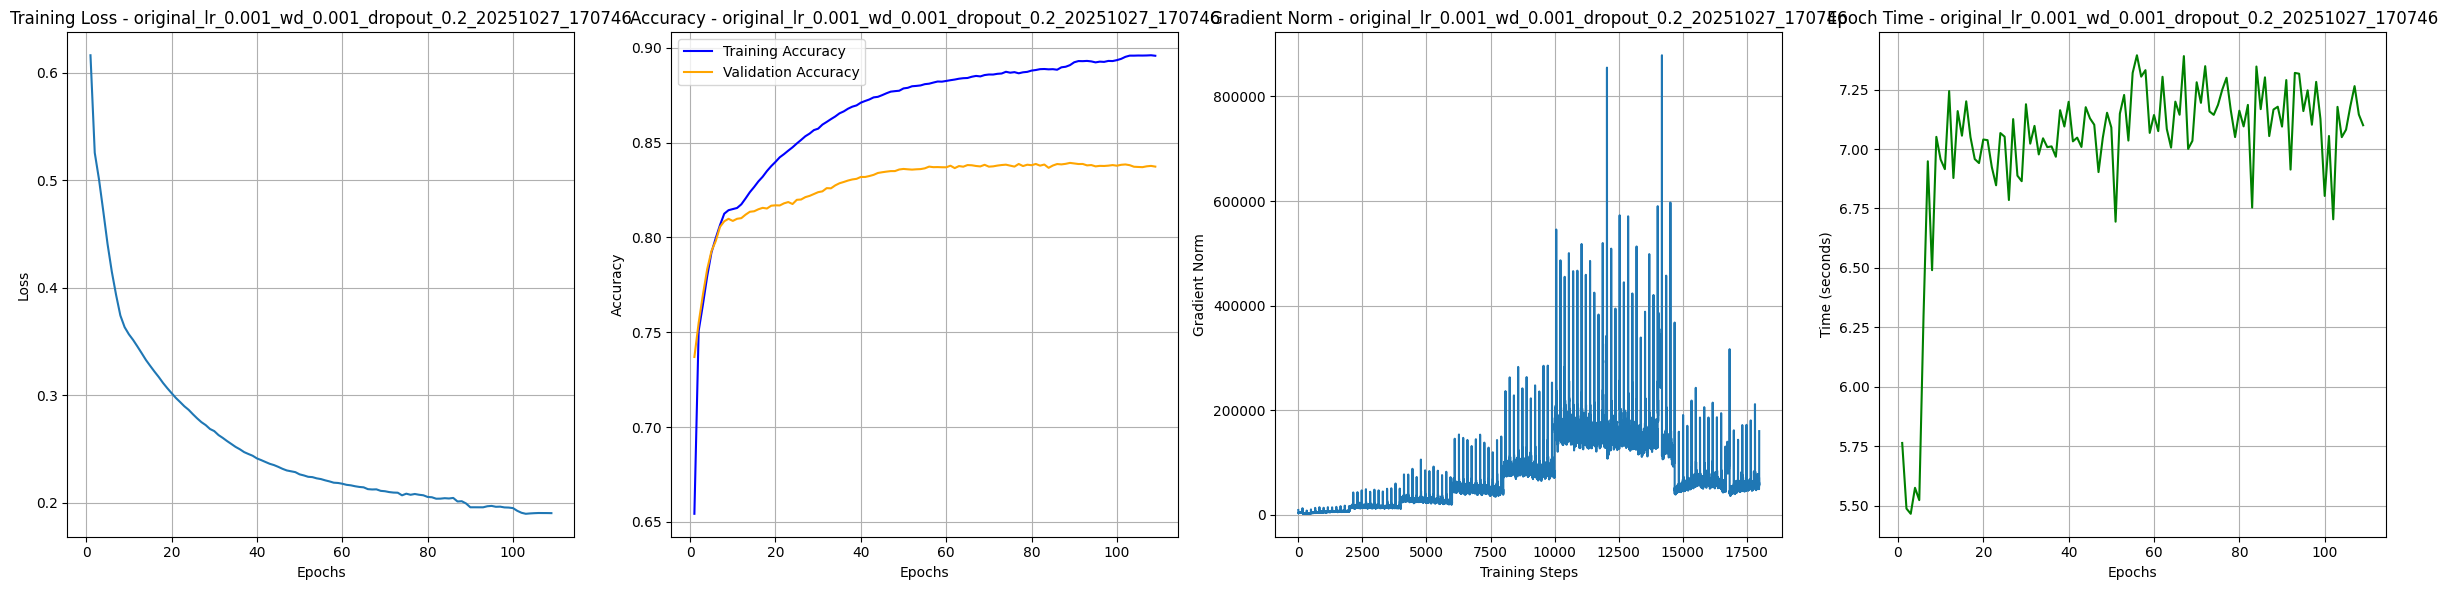


Running experiment: tads_lr_0.001_wd_0.001_dropout_0.2_20251027_172033
Parameters: {'lr': 0.001, 'weight_decay': 0.001, 'dropout_rate': 0.2, 'hidden_dims': [512, 256], 'd_model': 64, 'nhead': 4, 'num_layers': 2, 'num_groups': 30, 'output_dim_per_group': 4, 'max_epochs': 200, 'patience': 20, 'use_warmup': True, 'warmup_epochs': 10, 'warmup_base_lr': 0.0001, 'use_scheduler': True, 'scheduler_patience': 10, 'scheduler_factor': 0.8, 'scheduler_min_lr': 0.0005}
Parameters saved to output_data_15e-6_t18_30_r0.5_d1.0/params_tads_lr_0.001_wd_0.001_dropout_0.2_20251027_172033.json
Input detection_data shape: torch.Size([30000, 570])
After denoise, self.X shape: torch.Size([30000, 540]), effective_features: 540
Transformer grouped, self.X shape: torch.Size([30000, 30, 18]), max_group_size: 18
self.y shape: torch.Size([30000, 4, 30])
Input detection_data shape: torch.Size([30000, 570])
After denoise, self.X shape: torch.Size([30000, 540]), effective_features: 540
self.y shape: torch.Size([30000,

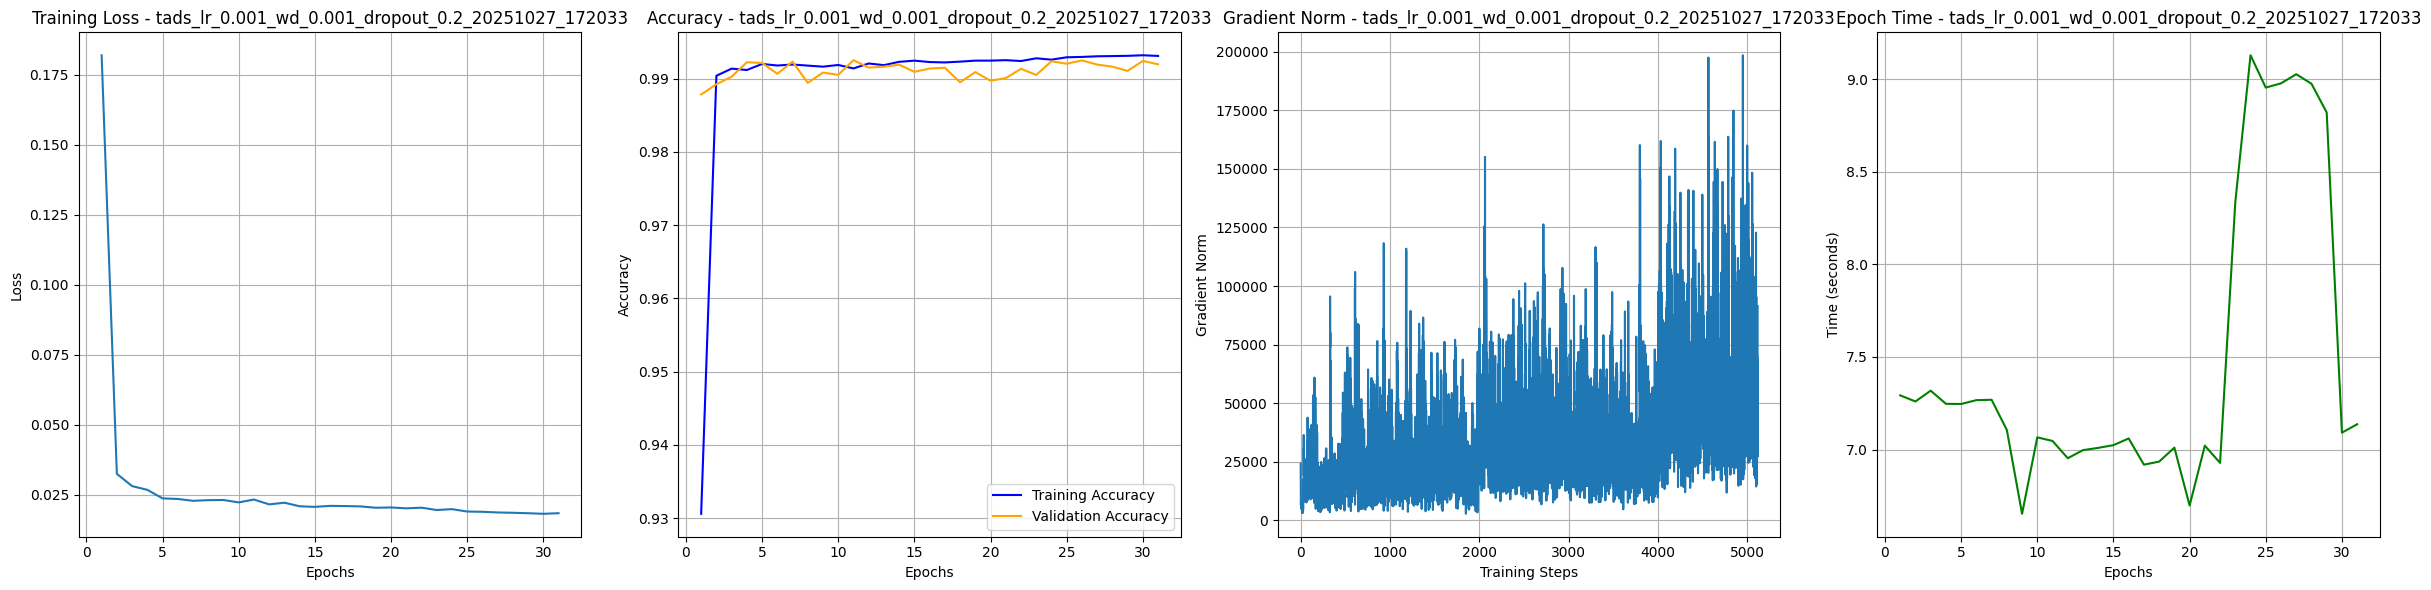


Running experiment: dnn_lr_0.001_wd_0.001_dropout_0.2_20251027_172427
Parameters: {'lr': 0.001, 'weight_decay': 0.001, 'dropout_rate': 0.2, 'hidden_dims': [512, 256], 'd_model': 64, 'nhead': 4, 'num_layers': 2, 'num_groups': 30, 'output_dim_per_group': 4, 'max_epochs': 200, 'patience': 20, 'use_warmup': True, 'warmup_epochs': 10, 'warmup_base_lr': 0.0001, 'use_scheduler': True, 'scheduler_patience': 10, 'scheduler_factor': 0.8, 'scheduler_min_lr': 0.0005}
Parameters saved to output_data_15e-6_t18_30_r0.5_d1.0/params_dnn_lr_0.001_wd_0.001_dropout_0.2_20251027_172427.json
Input detection_data shape: torch.Size([30000, 570])
After denoise, self.X shape: torch.Size([30000, 540]), effective_features: 540
Transformer not grouped, self.X shape: torch.Size([30000, 1, 540])
self.y shape: torch.Size([30000, 4, 30])
Input detection_data shape: torch.Size([30000, 570])
After denoise, self.X shape: torch.Size([30000, 540]), effective_features: 540
self.y shape: torch.Size([30000, 4, 30])
Epoch 1 L

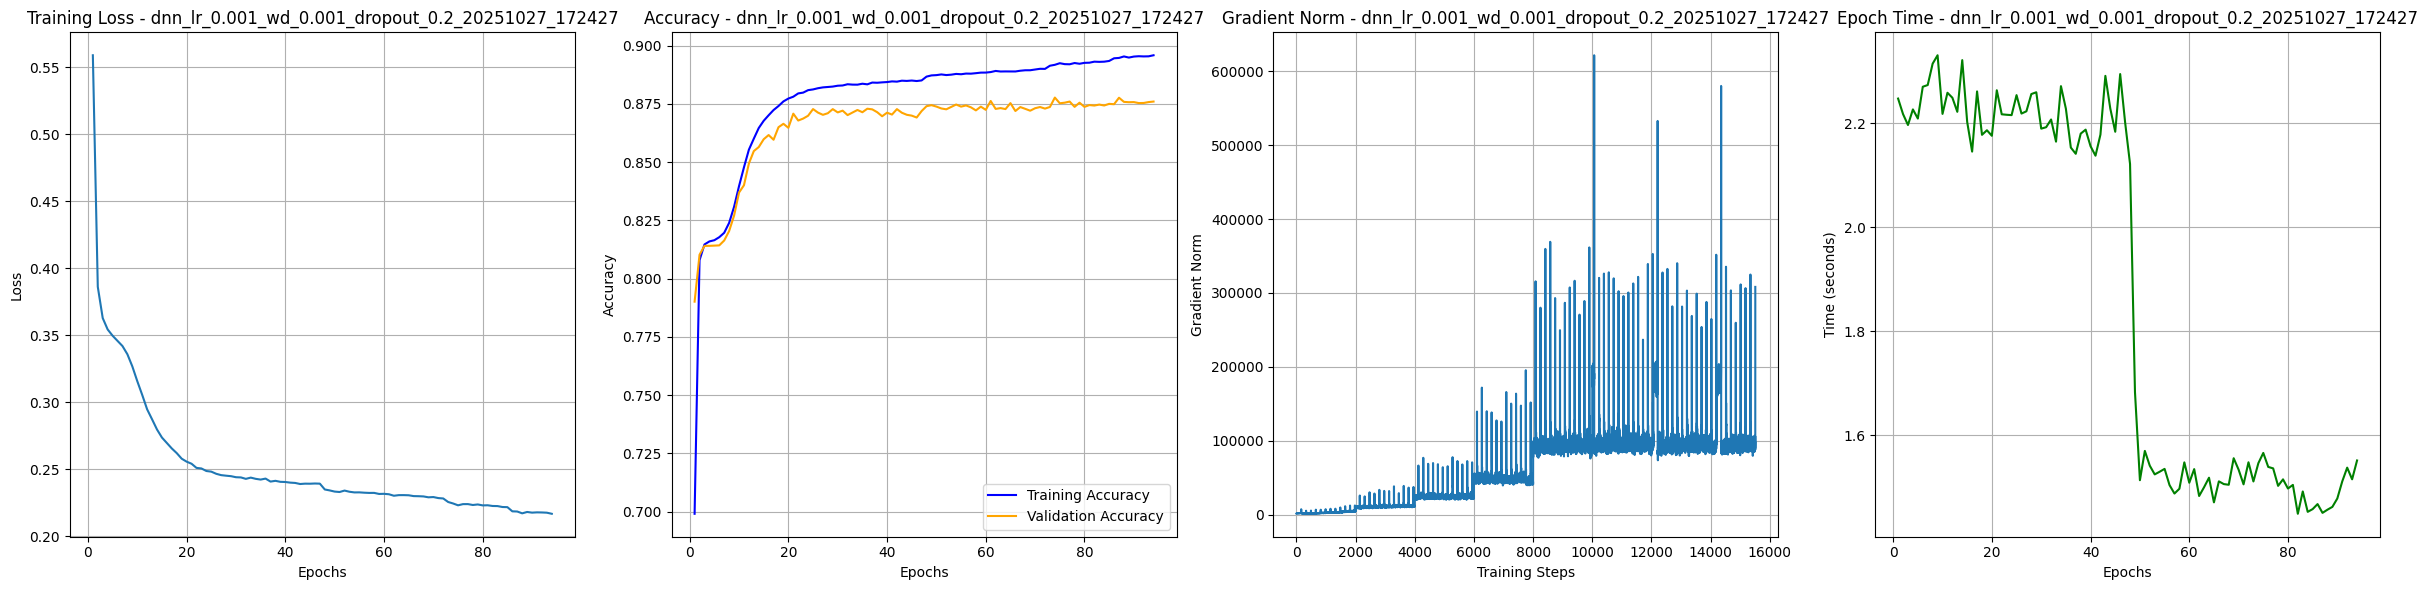

In [4]:
import os
os.environ['CUDA_LAUNCH_BLOCKING'] = '1'
os.environ['TORCH_USE_CUDA_DSA'] = '1'

# 实验参数和运行
# 每次实验改这里的参数
experiment_params = {
    "lr": 0.001,
    "weight_decay": 1e-3,
    "dropout_rate": 0.2,
    "hidden_dims": [512, 256],
    "d_model": 64,
    "nhead": 4,
    "num_layers": 2,
    "num_groups": data_params["sequence_length"],  # 组数（比如 20）
    "output_dim_per_group": 4,  # 每组输出 4 个值（4 个信号源）
    "max_epochs": 200,
    "patience": 20,
    "use_warmup": True,
    "warmup_epochs": 10,
    "warmup_base_lr": 0.0001,
    "use_scheduler": True,
    "scheduler_patience": 10,
    "scheduler_factor": 0.8,
    "scheduler_min_lr": 0.0005
}

# 消融实验设置
ablation_configs = [
    {"name": "original", "denoise": False, "group": False},  # 原始 Transformer
    # {"name": "grouped", "denoise": False, "group": True},   # 只分组
    # {"name": "denoised", "denoise": True, "group": False},  # 只去噪
    {"name": "tads", "denoise": True, "group": True},       # TADS
    {"name": "dnn", "denoise": True, "group": False}       # DNN
]

results = {}

for config in ablation_configs:
    model_type = config["name"]
    denoise = config["denoise"]
    group = config["group"]
    
    # 生成唯一的实验名称
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    experiment_name = f"{model_type}_lr_{experiment_params['lr']}_wd_{experiment_params['weight_decay']}_dropout_{experiment_params['dropout_rate']}_{timestamp}"
    
    print(f"\nRunning experiment: {experiment_name}")
    print("Parameters:", experiment_params)
    
    # 保存参数（JSON 格式）
    save_params_to_file(experiment_params, data_params, experiment_name, data_params["data_root"], format="json")
    
    # 根据实验设置调整数据集
    if denoise:
        gap = data_params["final_gap"] // 2
        effective_features = total_slot - 2 * gap  # 比如 390 - 2 * 15 = 360
    else:
        effective_features = total_slot  # 比如 390
    
    # 计算 group_size 和 num_groups
    if group:
        num_groups = data_params["sequence_length"]
        group_size = effective_features // data_params["sequence_length"]
        remainder = effective_features % data_params["sequence_length"]
        if remainder > 0:
            group_size += 1  # 使用 max_group_size
    else:
        num_groups = 1
        group_size = effective_features
    
    # 创建数据集
    dataset_transformer = SignalDataset(
        X, y, num_features=total_slot, sequence_length=data_params["sequence_length"], 
        final_gap=data_params["final_gap"], model_type="transformer", denoise=denoise, group=group
    )
    dataset_dnn = SignalDataset(
        X, y, num_features=total_slot, sequence_length=data_params["sequence_length"], 
        final_gap=data_params["final_gap"], model_type="dnn", denoise=denoise, group=group
    )
    
    # 划分数据集
    train_size = int(0.7 * len(dataset_transformer))
    val_size = int(0.15 * len(dataset_transformer))
    test_size = len(dataset_transformer) - train_size - val_size
    
    train_set_transformer, val_set_transformer, test_set_transformer = random_split(dataset_transformer, [train_size, val_size, test_size])
    train_loader_transformer = DataLoader(train_set_transformer, batch_size=128, shuffle=True)
    val_loader_transformer = DataLoader(val_set_transformer, batch_size=128)
    test_loader_transformer = DataLoader(test_set_transformer, batch_size=128)
    
    train_set_dnn, val_set_dnn, test_set_dnn = random_split(dataset_dnn, [train_size, val_size, test_size])
    train_loader_dnn = DataLoader(train_set_dnn, batch_size=128, shuffle=True)
    val_loader_dnn = DataLoader(val_set_dnn, batch_size=128)
    test_loader_dnn = DataLoader(test_set_dnn, batch_size=128)
    
    # 创建模型
    if model_type == "dnn":
        model = SignalDNN(
            input_dim=effective_features,
            hidden_dims=experiment_params["hidden_dims"],
            output_dim=4 * data_params["sequence_length"],  # 动态调整为 4 * 20
            dropout_rate=experiment_params["dropout_rate"],
            sequence_length=data_params["sequence_length"]  # 传递 sequence_length
        ).to(device)
        train_loader = train_loader_dnn
        val_loader = val_loader_dnn
        test_loader = test_loader_dnn
    else:
        model = TransformerModel(
            num_groups=num_groups,
            group_size=group_size,
            d_model=experiment_params["d_model"],
            nhead=experiment_params["nhead"],
            num_layers=experiment_params["num_layers"],
            output_dim_per_group=experiment_params["output_dim_per_group"],
            sequence_length=data_params["sequence_length"],
            group=group,
            dropout_rate=experiment_params["dropout_rate"]
        ).to(device)
        train_loader = train_loader_transformer
        val_loader = val_loader_transformer
        test_loader = test_loader_transformer
    
    optimizer = torch.optim.AdamW(model.parameters(), lr=experiment_params["lr"], weight_decay=experiment_params["weight_decay"])
    criterion = nn.BCEWithLogitsLoss()
    
    # 设置调度器
    if experiment_params["use_scheduler"]:
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, 'max', 
            patience=experiment_params["scheduler_patience"], 
            factor=experiment_params["scheduler_factor"], 
            min_lr=experiment_params["scheduler_min_lr"]
        )
    else:
        scheduler = None
    
    if experiment_params["use_warmup"]:
        warmup_scheduler = WarmupScheduler(
            optimizer, 
            warmup_epochs=experiment_params["warmup_epochs"], 
            base_lr=experiment_params["warmup_base_lr"], 
            target_lr=experiment_params["lr"]
        )
    else:
        warmup_scheduler = None
    
    # 训练
    train_loss, val_accuracy_list, train_accuracy_list, gradients, epoch_times, batch_times, total_time, val_inference_times = train_model_with_early_stopping(
        model, train_loader, val_loader, optimizer, scheduler, warmup_scheduler, criterion, device, 
        patience=experiment_params["patience"], experiment_name=experiment_name, max_epochs=experiment_params["max_epochs"],
        data_root=data_params["data_root"]
    )
    
    # 测试
    model.load_state_dict(torch.load(os.path.join(data_params["data_root"], f'best_model_{experiment_name}.pth'), weights_only=True))
    model.to(device)
    print(f"\nTest performance for {experiment_name}:")
    test_accuracy, test_inference_time = evaluate_model(model, test_loader, device)
    
    # 保存结果
    results[experiment_name] = {
        "train_loss": train_loss,
        "val_accuracy": val_accuracy_list,
        "train_accuracy": train_accuracy_list,
        "gradients": gradients,
        "epoch_times": epoch_times,
        "batch_times": batch_times,
        "total_time": total_time,
        "val_inference_times": val_inference_times,
        "test_accuracy": test_accuracy,
        "test_inference_time": test_inference_time
    }
    
    # 可视化
    plot_results(train_loss, val_accuracy_list, train_accuracy_list, gradients, epoch_times, experiment_name, data_params["data_root"])

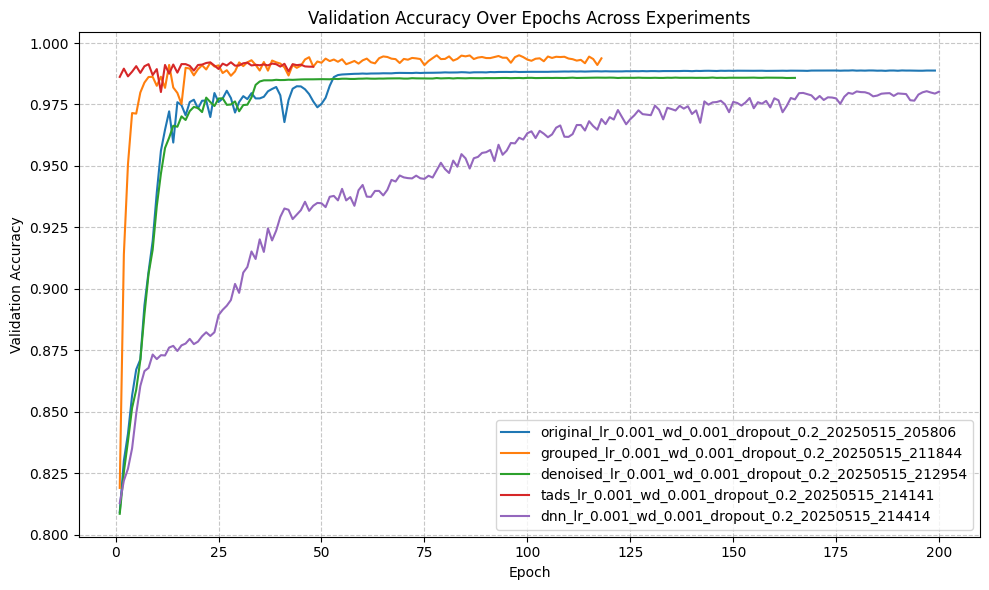

In [15]:
import matplotlib.pyplot as plt
import numpy as np

# 假设 results 包含五组实验的结果
# results[experiment_name] = {"train_loss": ..., "val_accuracy": ..., "train_accuracy": ..., "epoch_times": ..., ...}
plt.figure(figsize=(10, 6))
for exp_name, result in results.items():
    epochs = np.arange(1, len(result["val_accuracy"]) + 1)
    plt.plot(epochs, result["val_accuracy"], label=exp_name)
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy Over Epochs Across Experiments")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig(os.path.join(data_params["data_root"], "val_accuracy_comparison.png"))
plt.show()

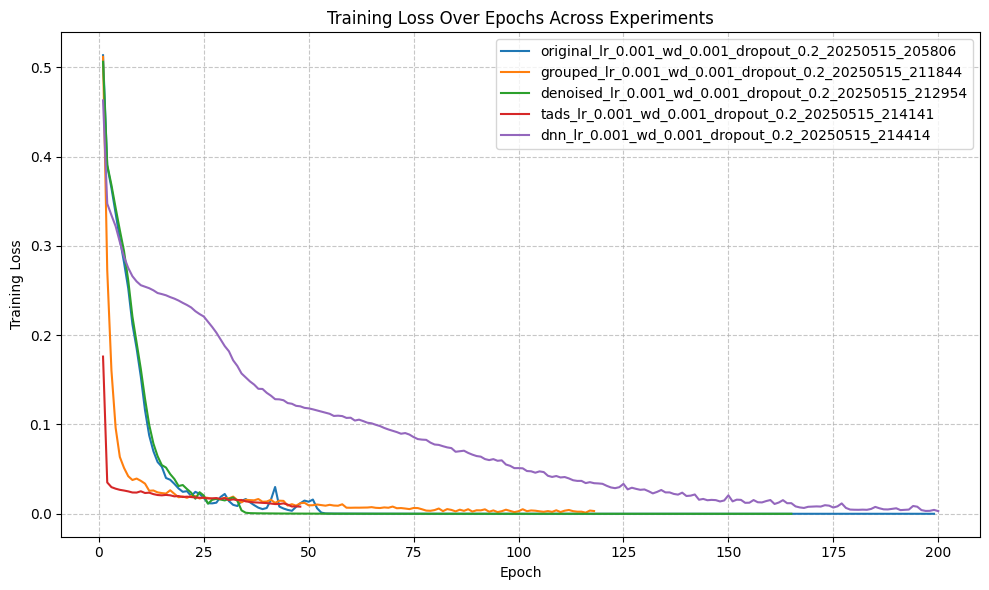

In [16]:
plt.figure(figsize=(10, 6))
for exp_name, result in results.items():
    epochs = np.arange(1, len(result["train_loss"]) + 1)
    plt.plot(epochs, result["train_loss"], label=exp_name)
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss Over Epochs Across Experiments")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig(os.path.join(data_params["data_root"], "train_loss_comparison.png"))
plt.show()

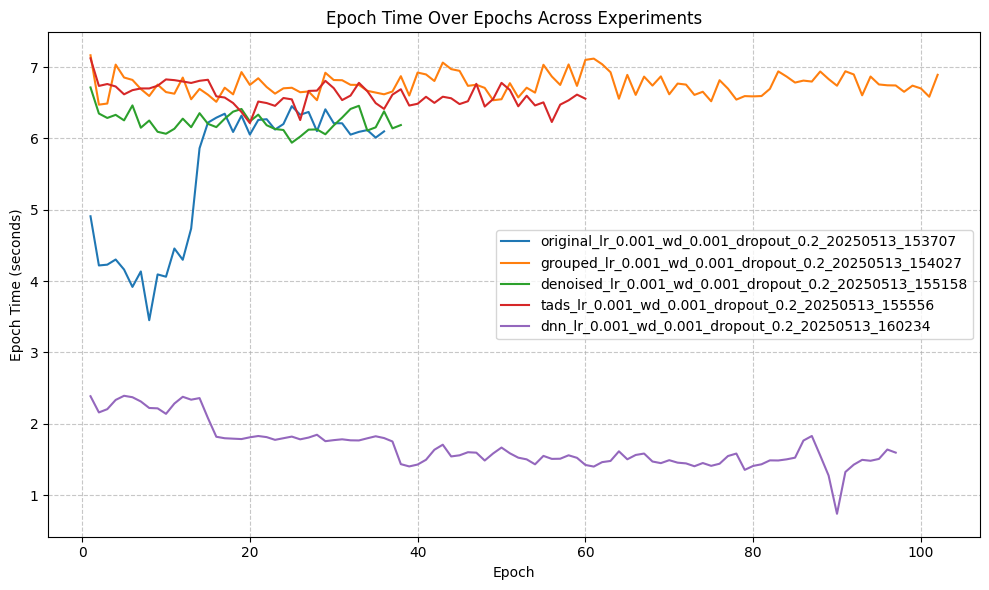

In [6]:
plt.figure(figsize=(10, 6))
for exp_name, result in results.items():
    epochs = np.arange(1, len(result["epoch_times"]) + 1)
    plt.plot(epochs, result["epoch_times"], label=exp_name)
plt.xlabel("Epoch")
plt.ylabel("Epoch Time (seconds)")
plt.title("Epoch Time Over Epochs Across Experiments")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig(os.path.join(data_params["data_root"], "epoch_time_comparison.png"))
plt.show()

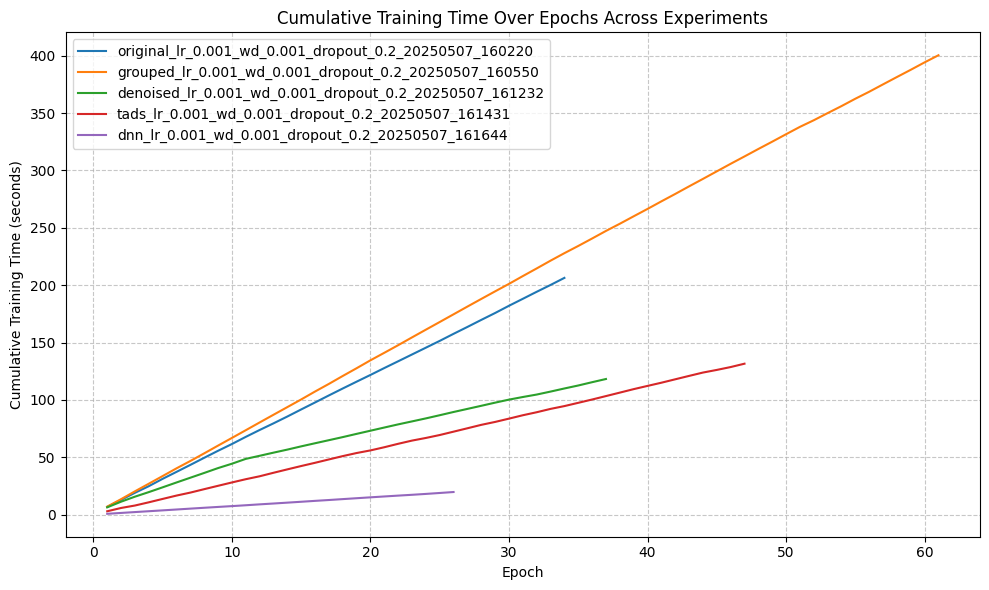

In [8]:
plt.figure(figsize=(10, 6))
for exp_name, result in results.items():
    epochs = np.arange(1, len(result["epoch_times"]) + 1)
    cumulative_times = np.cumsum(result["epoch_times"])
    plt.plot(epochs, cumulative_times, label=exp_name)
plt.xlabel("Epoch")
plt.ylabel("Cumulative Training Time (seconds)")
plt.title("Cumulative Training Time Over Epochs Across Experiments")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig(os.path.join(data_params["data_root"], "cumulative_time_comparison.png"))
plt.show()

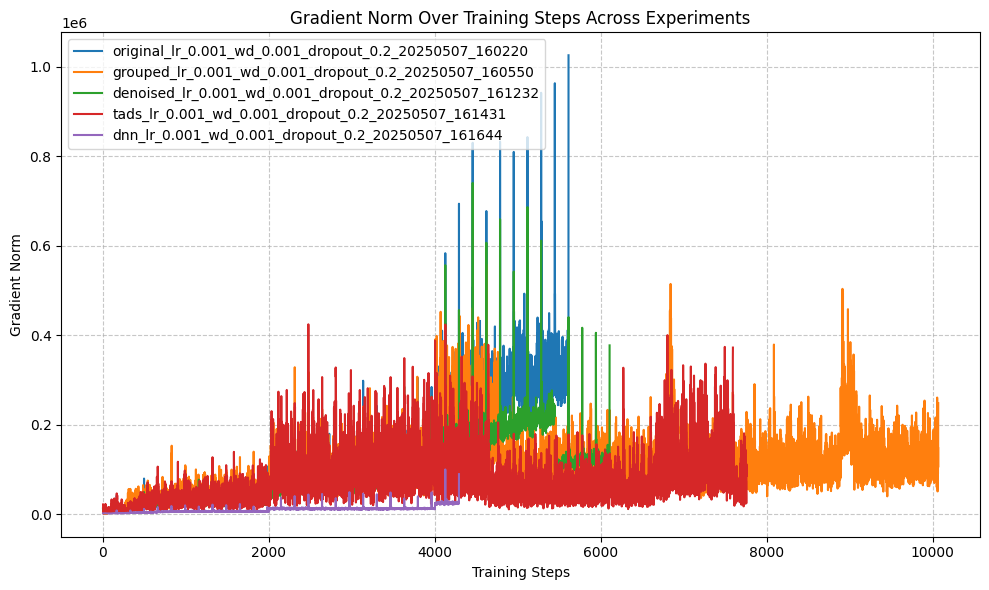

In [9]:
plt.figure(figsize=(10, 6))
for exp_name, result in results.items():
    steps = np.arange(1, len(result["gradients"]) + 1)
    plt.plot(steps, result["gradients"], label=exp_name)
plt.xlabel("Training Steps")
plt.ylabel("Gradient Norm")
plt.title("Gradient Norm Over Training Steps Across Experiments")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig(os.path.join(data_params["data_root"], "gradient_norm_comparison.png"))
plt.show()

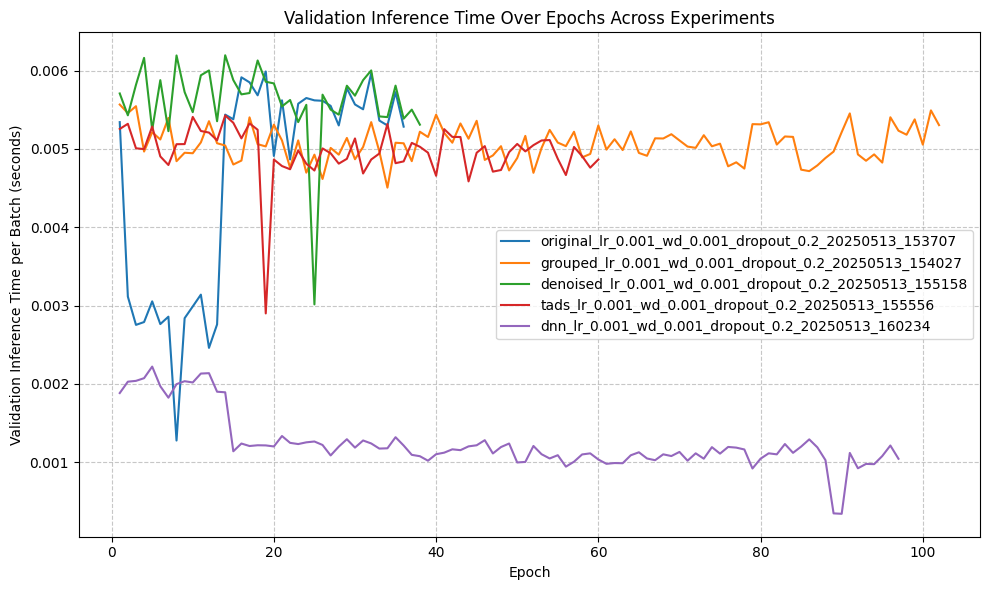

In [7]:
plt.figure(figsize=(10, 6))
for exp_name, result in results.items():
    epochs = np.arange(1, len(result["val_inference_times"]) + 1)
    plt.plot(epochs, result["val_inference_times"], label=exp_name)
plt.xlabel("Epoch")
plt.ylabel("Validation Inference Time per Batch (seconds)")
plt.title("Validation Inference Time Over Epochs Across Experiments")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig(os.path.join(data_params["data_root"], "val_inference_time_comparison.png"))
plt.show()

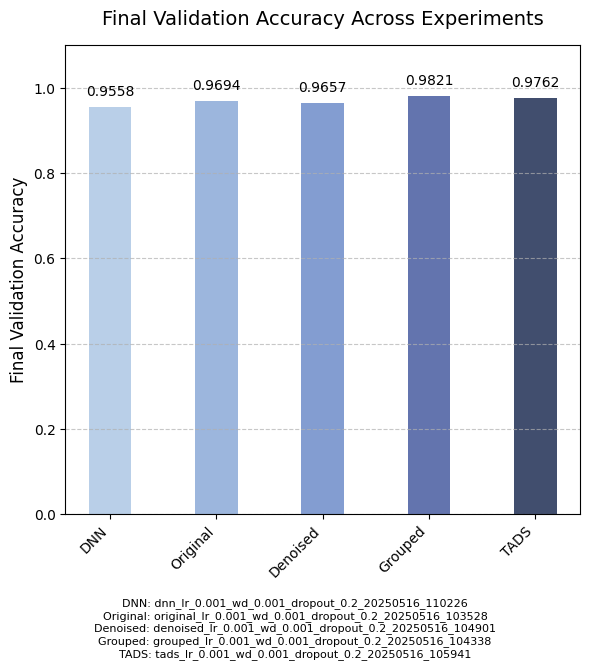

In [10]:
import matplotlib.pyplot as plt
import numpy as np

# 调整实验顺序
short_names = ['DNN', 'Original', 'Denoised', 'Grouped', 'TADS']  # 新顺序
exp_names = list(results.keys())  # 原始实验名称列表

# 根据新顺序重新映射实验名称
original_short_names = ['Original', 'Grouped', 'Denoised', 'TADS', 'DNN']
original_indices = {name: idx for idx, name in enumerate(original_short_names)}  # 原始顺序的索引
sorted_results = [results[exp_names[original_indices[name]]] for name in short_names]  # 按新顺序排列 results
name_mapping = dict(zip(short_names, [exp_names[original_indices[name]] for name in short_names]))  # 新顺序的映射

# 柱状图颜色和宽度
# bar_colors = ['#B9CFE8', '#9CB6DD', '#839DD1', '#6374AE', '#414E6E']#蓝色
bar_colors =['#F0E0B0', '#E8C98A', '#D9B17E', '#C28D6A', '#8A5C4E'] #红黄
bar_width = 0.4
bar_positions = np.arange(len(short_names))

# 子图 1：最终验证准确率
plt.figure(figsize=(6, 6))  # 调整为单独图的大小
final_val_accs = [result["val_accuracy"][-1] for result in sorted_results]  # 按新顺序获取数据
bars = plt.bar(bar_positions, final_val_accs, color=bar_colors, width=bar_width)
plt.ylabel("Final Validation Accuracy", fontsize=12)
plt.title("Final Validation Accuracy Across Experiments", fontsize=14, pad=15)
plt.xticks(bar_positions, short_names, rotation=45, ha='right', fontsize=10)
plt.ylim(0, 1.1)
for bar, value in zip(bars, final_val_accs):
    offset = bar.get_height() * 0.02  # 动态偏移量
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + offset, f'{value:.4f}', ha='center', va='bottom', fontsize=10)
plt.grid(True, axis='y', linestyle='--', alpha=0.7)

# 添加完整实验名称说明
plt.figtext(0.5, -0.1, 
            "\n".join([f"{short}: {long}" for short, long in name_mapping.items()]),
            ha="center", fontsize=8, wrap=True)

plt.tight_layout()
plt.savefig(os.path.join(data_params["data_root"], "final_validation_accuracy_fixed.png"), bbox_inches='tight')
plt.show()

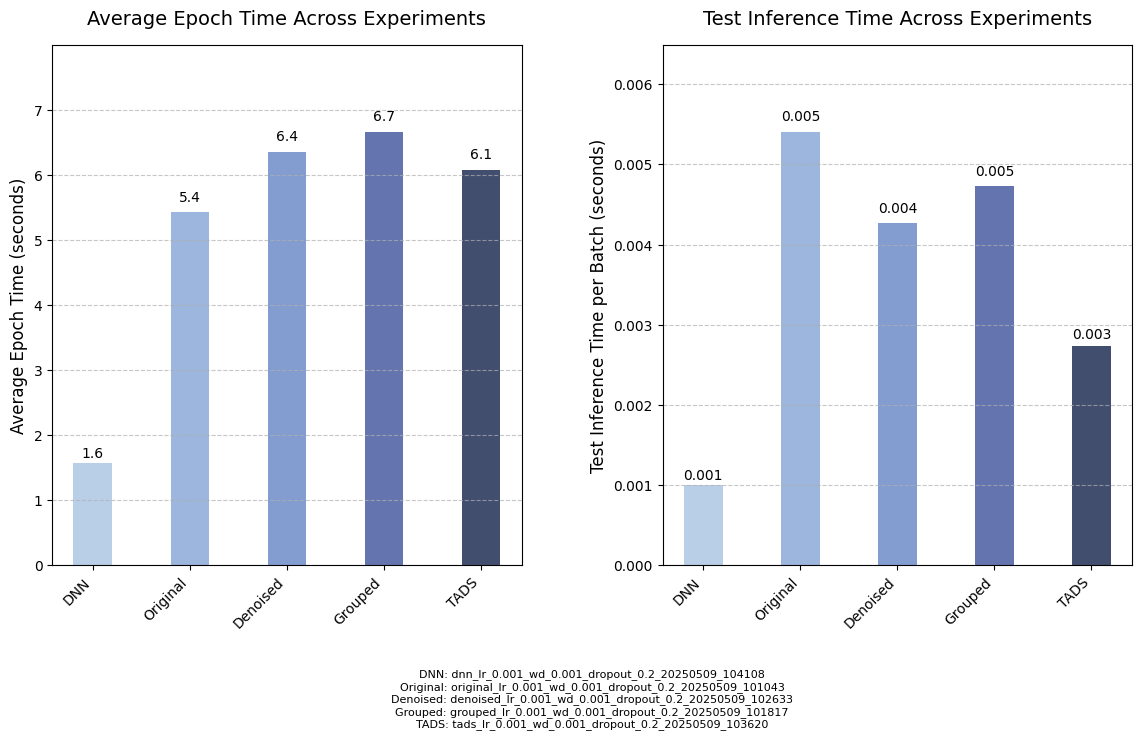

In [9]:
import matplotlib.pyplot as plt
import numpy as np

# 调整实验顺序
short_names = ['DNN', 'Original', 'Denoised', 'Grouped', 'TADS']  # 新顺序
exp_names = list(results.keys())  # 原始实验名称列表

# 根据新顺序重新映射实验名称
original_short_names = ['Original', 'Grouped', 'Denoised', 'TADS', 'DNN']
original_indices = {name: idx for idx, name in enumerate(original_short_names)}  # 原始顺序的索引
sorted_results = [results[exp_names[original_indices[name]]] for name in short_names]  # 按新顺序排列 results
name_mapping = dict(zip(short_names, [exp_names[original_indices[name]] for name in short_names]))  # 新顺序的映射

# 柱状图颜色和宽度
bar_colors = ['#B9CFE8', '#9CB6DD', '#839DD1', '#6374AE', '#414E6E']
bar_width = 0.4
bar_positions = np.arange(len(short_names))

# 创建包含两个子图的画布
plt.figure(figsize=(12, 8))

# 子图 2：平均轮次时间
plt.subplot(1, 2, 1)
avg_epoch_times = [np.mean(result["epoch_times"]) for result in sorted_results]  # 按新顺序获取数据
bars = plt.bar(bar_positions, avg_epoch_times, color=bar_colors, width=bar_width)
plt.ylabel("Average Epoch Time (seconds)", fontsize=12)
plt.title("Average Epoch Time Across Experiments", fontsize=14, pad=15)
plt.xticks(bar_positions, short_names, rotation=45, ha='right', fontsize=10)
plt.ylim(0, max(avg_epoch_times) * 1.2)
for bar, value in zip(bars, avg_epoch_times):
    offset = bar.get_height() * 0.02
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + offset, f'{value:.1f}', ha='center', va='bottom', fontsize=10)
plt.grid(True, axis='y', linestyle='--', alpha=0.7)

# 子图 3：测试推理时间
plt.subplot(1, 2, 2)
test_inference_times = [result["test_inference_time"] for result in sorted_results]  # 按新顺序获取数据
bars = plt.bar(bar_positions, test_inference_times, color=bar_colors, width=bar_width)
plt.ylabel("Test Inference Time per Batch (seconds)", fontsize=12)
plt.title("Test Inference Time Across Experiments", fontsize=14, pad=15)
plt.xticks(bar_positions, short_names, rotation=45, ha='right', fontsize=10)
plt.ylim(0, max(test_inference_times) * 1.2)
for bar, value in zip(bars, test_inference_times):
    offset = bar.get_height() * 0.02
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + offset, f'{value:.3f}', ha='center', va='bottom', fontsize=10)
plt.grid(True, axis='y', linestyle='--', alpha=0.7)

# 添加完整实验名称说明
plt.figtext(0.5, 0.05, 
            "\n".join([f"{short}: {long}" for short, long in name_mapping.items()]),
            ha="center", fontsize=8, wrap=True)

plt.subplots_adjust(left=0.05, right=0.95, top=0.9, bottom=0.25, wspace=0.3)
plt.savefig(os.path.join(data_params["data_root"], "epoch_and_inference_time_comparison_fixed.png"))
plt.show()

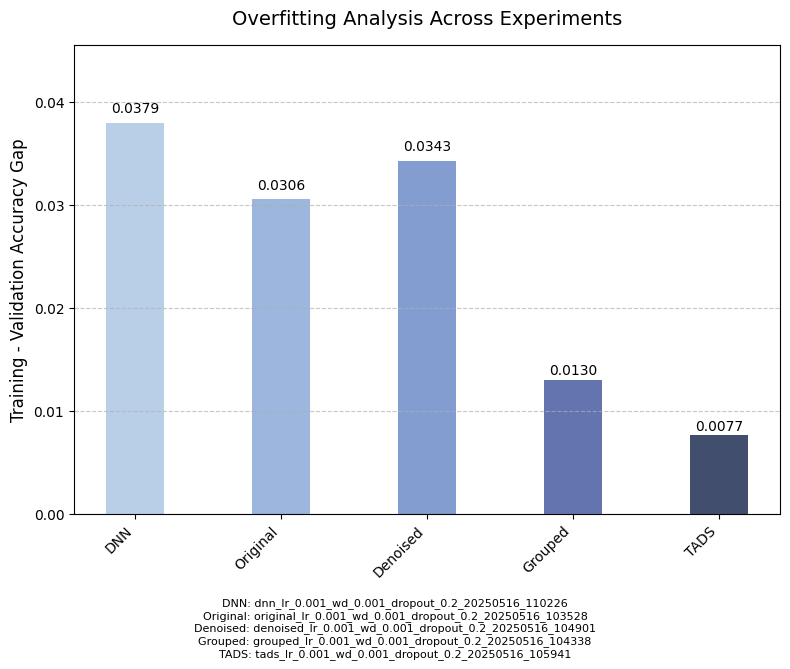

In [13]:
import matplotlib.pyplot as plt
import numpy as np

# 调整实验顺序
short_names = ['DNN', 'Original', 'Denoised', 'Grouped', 'TADS']  # 新顺序
exp_names = list(results.keys())  # 原始实验名称列表

# 根据新顺序重新映射实验名称
# 原始 short_names 的顺序是 ['Original', 'Grouped', 'Denoised', 'TADS', 'DNN']
original_short_names = ['Original', 'Grouped', 'Denoised', 'TADS', 'DNN']
original_indices = {name: idx for idx, name in enumerate(original_short_names)}  # 原始顺序的索引
sorted_results = [results[exp_names[original_indices[name]]] for name in short_names]  # 按新顺序排列 results
name_mapping = dict(zip(short_names, [exp_names[original_indices[name]] for name in short_names]))  # 新顺序的映射

# 柱状图颜色和宽度（保持不变）
bar_colors = ['#B9CFE8', '#9CB6DD', '#839DD1', '#6374AE', '#414E6E']
bar_width = 0.4
bar_positions = np.arange(len(short_names))

# 绘制过拟合分析图
plt.figure(figsize=(8, 6))
gaps = [result["train_accuracy"][-1] - result["val_accuracy"][-1] for result in sorted_results]  # 按新顺序获取数据
bars = plt.bar(bar_positions, gaps, color=bar_colors, width=bar_width)
plt.ylabel("Training - Validation Accuracy Gap", fontsize=12)
plt.title("Overfitting Analysis Across Experiments", fontsize=14, pad=15)
plt.xticks(bar_positions, short_names, rotation=45, ha='right', fontsize=10)
plt.ylim(0, max(gaps) * 1.2)
for bar, value in zip(bars, gaps):
    offset = bar.get_height() * 0.02
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + offset, f'{value:.4f}', ha='center', va='bottom', fontsize=10)
plt.grid(True, axis='y', linestyle='--', alpha=0.7)

# 添加完整实验名称说明
plt.figtext(0.5, -0.1, 
            "\n".join([f"{short}: {long}" for short, long in name_mapping.items()]),
            ha="center", fontsize=8, wrap=True)

plt.tight_layout()
plt.savefig(os.path.join(data_params["data_root"], "overfitting_comparison_fixed.png"), bbox_inches='tight')
plt.show()

In [11]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6  # 转换为百万

plt.figure(figsize=(8, 6))
exp_names = list(results.keys())
param_counts = []
for exp_name in exp_names:
    if "dnn" in exp_name:
        model = SignalDNN(
            input_dim=effective_features,
            hidden_dims=experiment_params["hidden_dims"],
            output_dim=40,
            dropout_rate=experiment_params["dropout_rate"]
        )
    else:
        denoise = "denoise" in exp_name or "tads" in exp_name
        group = "grouped" in exp_name or "tads" in exp_name
        if denoise:
            effective_features = total_slot - 2 * (data_params["final_gap"] // 2)
        else:
            effective_features = total_slot
        num_groups = data_params["sequence_length"] if group else 1
        group_size = effective_features // data_params["sequence_length"] if group else effective_features
        model = TransformerModel(
            num_groups=num_groups,
            group_size=group_size,
            d_model=experiment_params["d_model"],
            nhead=experiment_params["nhead"],
            num_layers=experiment_params["num_layers"],
            output_dim_per_group=experiment_params["output_dim_per_group"],
            sequence_length=data_params["sequence_length"],
            group=group,
            dropout_rate=experiment_params["dropout_rate"]
        )
    param_counts.append(count_parameters(model))

bar_positions = np.arange(len(short_names))
bars = plt.bar(bar_positions, param_counts, color=bar_colors, width=bar_width)
plt.ylabel("Number of Parameters (Millions)", fontsize=12)
plt.title("Model Complexity Across Experiments", fontsize=14, pad=15)
plt.xticks(bar_positions, short_names, rotation=45, ha='right', fontsize=10)
plt.ylim(0, max(param_counts) * 1.2)
for bar, value in zip(bars, param_counts):
    offset = bar.get_height() * 0.02
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + offset, f'{value:.4f}', ha='center', va='bottom', fontsize=10)
plt.grid(True, axis='y', linestyle='--', alpha=0.7)

# 添加完整实验名称说明
plt.figtext(0.5, -0.1, 
            "\n".join([f"{short}: {long}" for short, long in zip(short_names, exp_names)]),
            ha="center", fontsize=8, wrap=True)

plt.tight_layout()
plt.savefig(os.path.join(data_params["data_root"], "param_count_comparison_fixed.png"), bbox_inches='tight')
plt.show()

TypeError: SignalDNN.__init__() missing 1 required positional argument: 'sequence_length'

<Figure size 800x600 with 0 Axes>

In [25]:
import pandas as pd

# 构建表格数据
table_data = {
    "Experiment": list(results.keys()),
    "Final Validation Accuracy": [result["val_accuracy"][-1] for result in results.values()],
    "Average Epoch Time (s)": [np.mean(result["epoch_times"]) for result in results.values()],
    "Test Inference Time (s/batch)": [result["test_inference_time"] for result in results.values()],
    "Training-Validation Accuracy Gap": [result["train_accuracy"][-1] - result["val_accuracy"][-1] for result in results.values()],
    "Number of Parameters (M)": param_counts  # 从之前的代码中获取
}

# 创建 DataFrame 并保存为 CSV
df = pd.DataFrame(table_data)
df.to_csv(os.path.join(data_params["data_root"], "comparison_table.csv"), index=False)
print(df)

                                          Experiment  \
0  original_lr_0.001_wd_0.001_dropout_0.2_2025041...   
1  grouped_lr_0.001_wd_0.001_dropout_0.2_20250411...   
2  denoised_lr_0.001_wd_0.001_dropout_0.2_2025041...   
3  tads_lr_0.001_wd_0.001_dropout_0.2_20250411_10...   
4  dnn_lr_0.001_wd_0.001_dropout_0.2_20250411_104244   

   Final Validation Accuracy  Average Epoch Time (s)  \
0                   0.896056                2.760145   
1                   0.971739                2.990198   
2                   0.884639                2.781115   
3                   0.980861                2.997932   
4                   0.886150                0.745582   

   Test Inference Time (s/batch)  Training-Validation Accuracy Gap  \
0                       0.000999                          0.103944   
1                       0.001088                          0.024847   
2                       0.000951                          0.115361   
3                       0.001052              

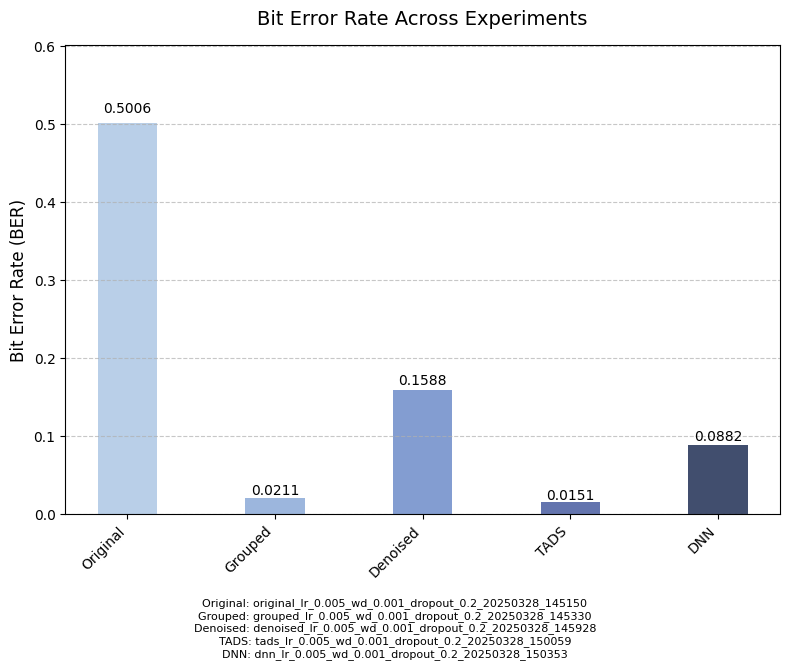

In [15]:
plt.figure(figsize=(8, 6))
exp_names = list(results.keys())
ber_values = [1 - result["val_accuracy"][-1] for result in results.values()]  # 计算 BER
bar_positions = np.arange(len(short_names))
bars = plt.bar(bar_positions, ber_values, color=bar_colors, width=bar_width)
plt.ylabel("Bit Error Rate (BER)", fontsize=12)
plt.title("Bit Error Rate Across Experiments", fontsize=14, pad=15)
plt.xticks(bar_positions, short_names, rotation=45, ha='right', fontsize=10)
plt.ylim(0, max(ber_values) * 1.2)
for bar, value in zip(bars, ber_values):
    offset = bar.get_height() * 0.02
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + offset, f'{value:.4f}', ha='center', va='bottom', fontsize=10)
plt.grid(True, axis='y', linestyle='--', alpha=0.7)

# 添加完整实验名称说明
plt.figtext(0.5, -0.1, 
            "\n".join([f"{short}: {long}" for short, long in zip(short_names, exp_names)]),
            ha="center", fontsize=8, wrap=True)

plt.tight_layout()
plt.savefig(os.path.join(data_params["data_root"], "ber_comparison.png"), bbox_inches='tight')
plt.show()

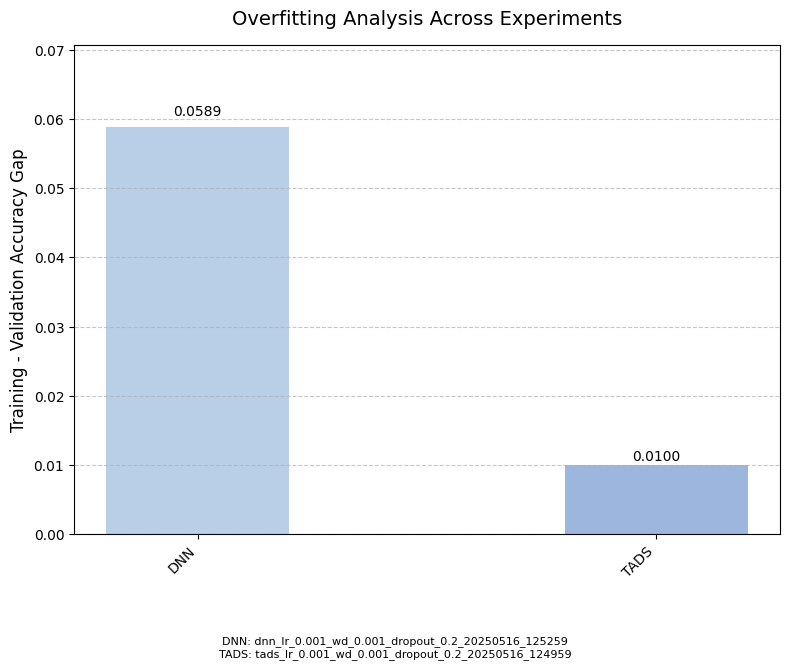

In [21]:
import matplotlib.pyplot as plt
import numpy as np

# 调整实验顺序
short_names = ['DNN', 'TADS']  # 新顺序
exp_names = list(results.keys())  # 原始实验名称列表

# 根据新顺序重新映射实验名称
# 原始 short_names 的顺序是 ['Original', 'Grouped', 'Denoised', 'TADS', 'DNN']
original_short_names = ['TADS', 'DNN']
original_indices = {name: idx for idx, name in enumerate(original_short_names)}  # 原始顺序的索引
sorted_results = [results[exp_names[original_indices[name]]] for name in short_names]  # 按新顺序排列 results
name_mapping = dict(zip(short_names, [exp_names[original_indices[name]] for name in short_names]))  # 新顺序的映射

# 柱状图颜色和宽度（保持不变）
bar_colors = ['#B9CFE8', '#9CB6DD', '#839DD1', '#6374AE', '#414E6E']
bar_width = 0.4
bar_positions = np.arange(len(short_names))

# 绘制过拟合分析图
plt.figure(figsize=(8, 6))
gaps = [result["train_accuracy"][-1] - result["val_accuracy"][-1] for result in sorted_results]  # 按新顺序获取数据
bars = plt.bar(bar_positions, gaps, color=bar_colors, width=bar_width)
plt.ylabel("Training - Validation Accuracy Gap", fontsize=12)
plt.title("Overfitting Analysis Across Experiments", fontsize=14, pad=15)
plt.xticks(bar_positions, short_names, rotation=45, ha='right', fontsize=10)
plt.ylim(0, max(gaps) * 1.2)
for bar, value in zip(bars, gaps):
    offset = bar.get_height() * 0.02
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + offset, f'{value:.4f}', ha='center', va='bottom', fontsize=10)
plt.grid(True, axis='y', linestyle='--', alpha=0.7)

# 添加完整实验名称说明
plt.figtext(0.5, -0.1, 
            "\n".join([f"{short}: {long}" for short, long in name_mapping.items()]),
            ha="center", fontsize=8, wrap=True)

plt.tight_layout()
plt.savefig(os.path.join(data_params["data_root"], "overfitting_comparison_fixed.png"), bbox_inches='tight')
plt.show()

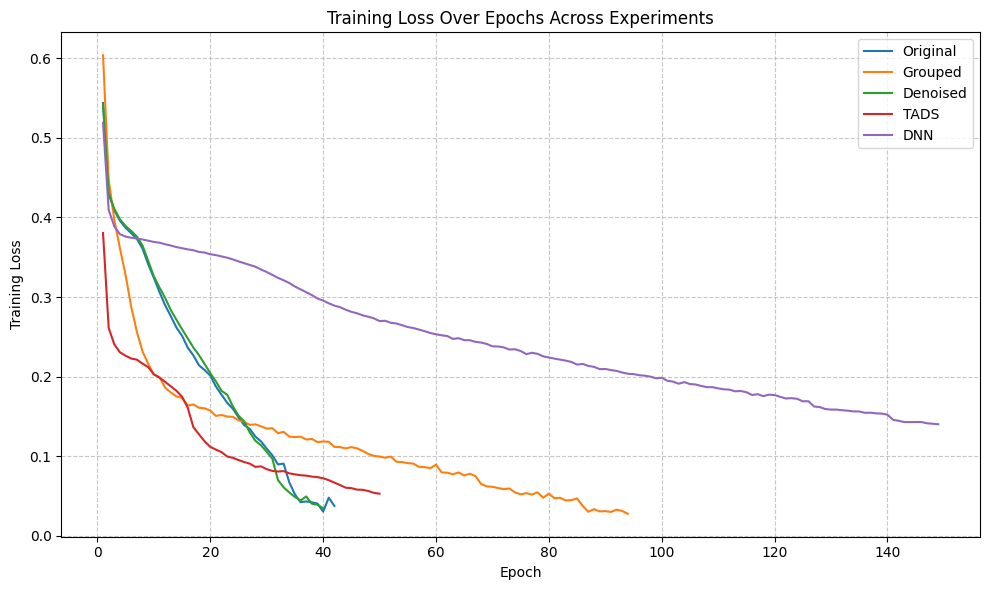

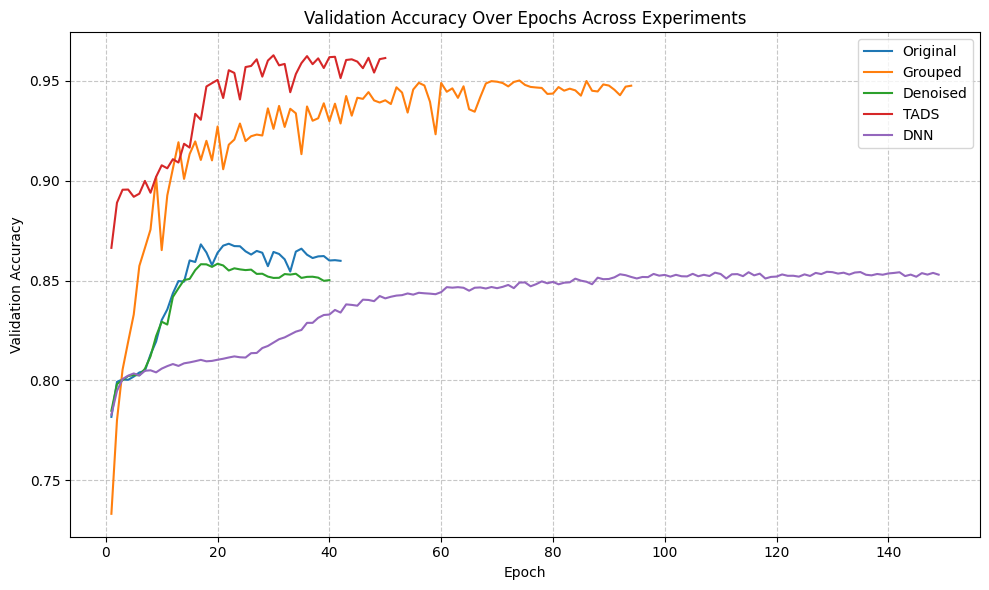

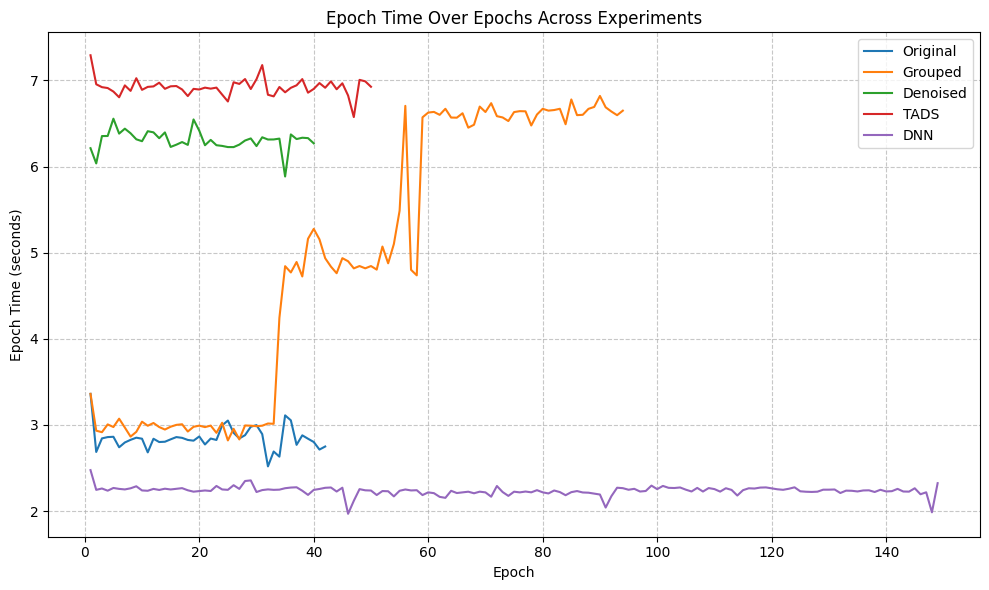

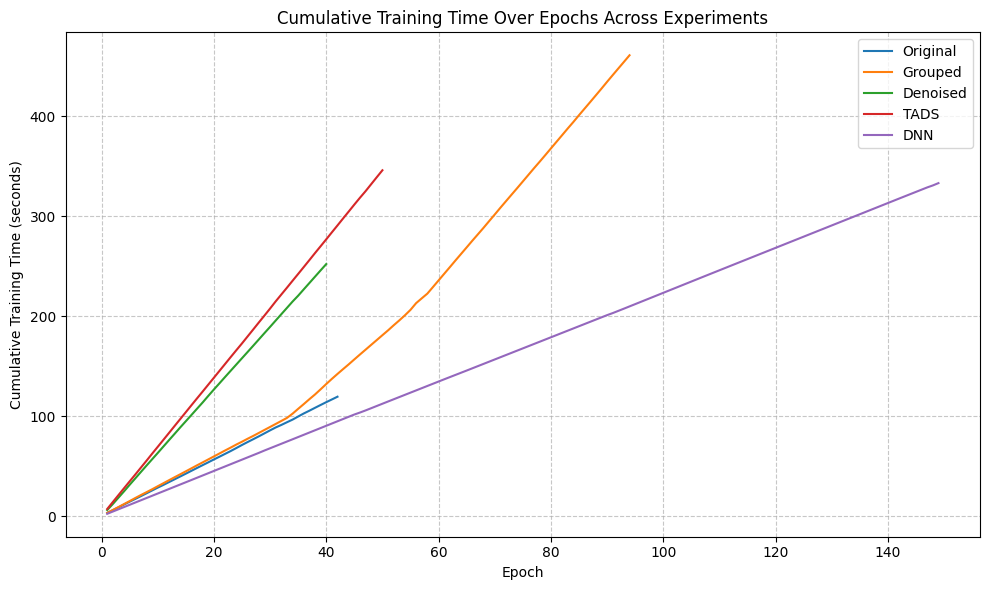

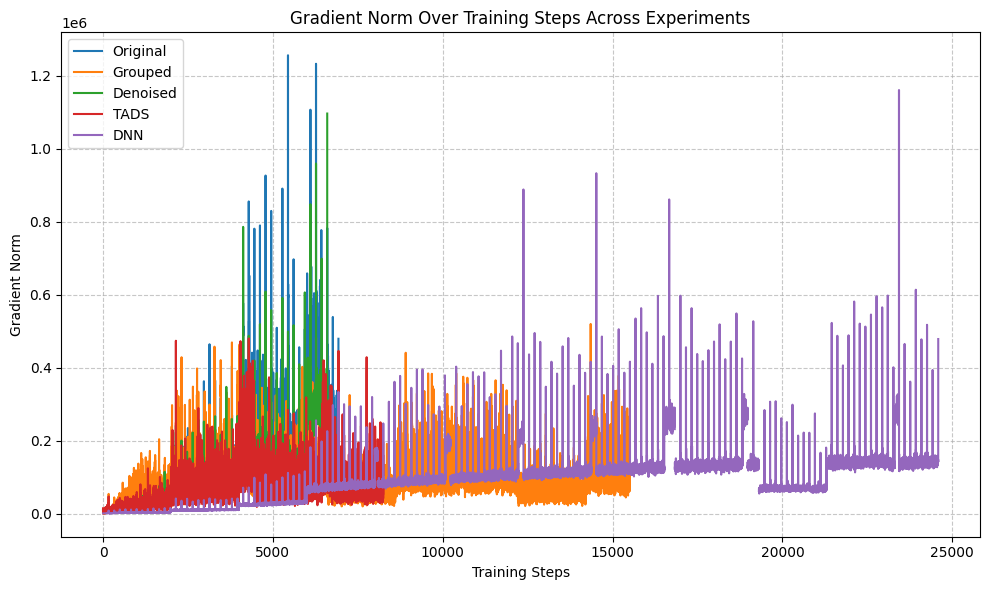

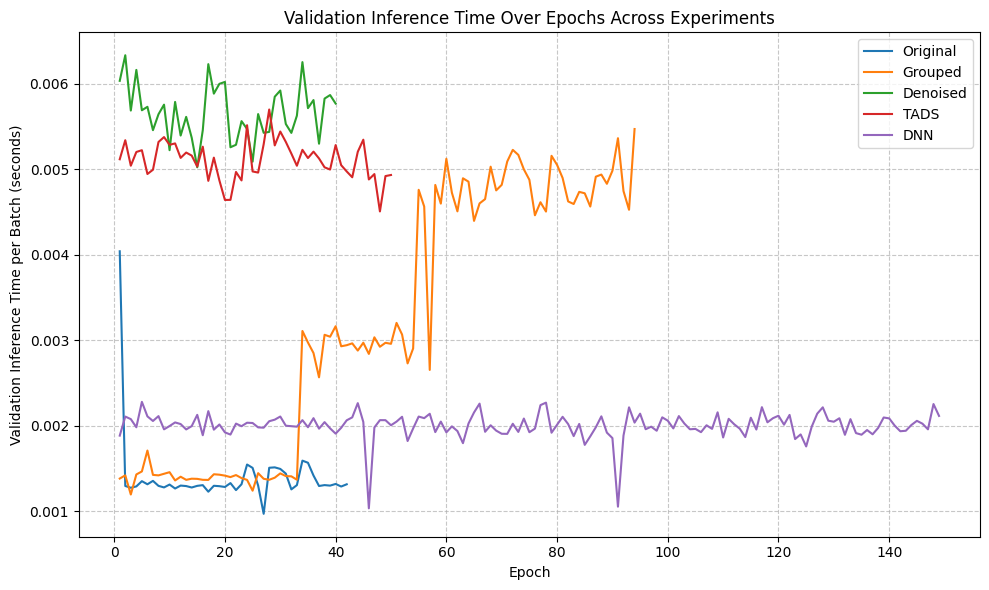

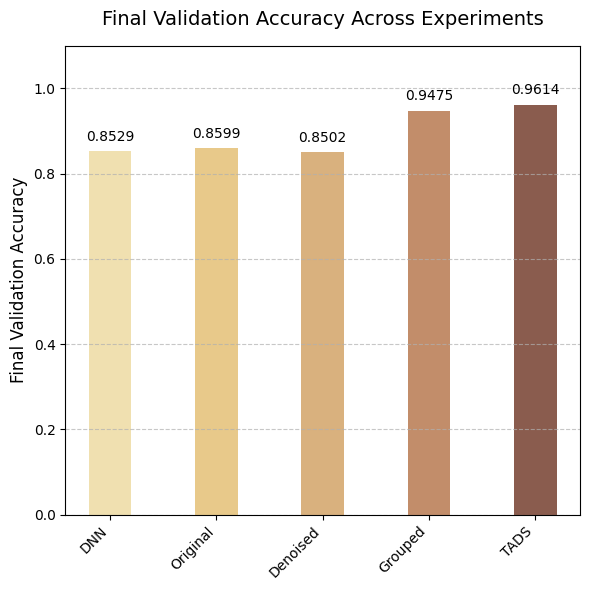

In [7]:
def get_short_name(exp_name):
    """从实验文件名中提取短名称"""
    if 'dnn_' in exp_name:
        return 'DNN'
    elif 'tads_' in exp_name:
        return 'TADS'
    elif 'denoised_' in exp_name:
        return 'Denoised'
    elif 'grouped_' in exp_name:
        return 'Grouped'
    elif 'original_' in exp_name:
        return 'Original'
    else:
        return exp_name  # 如果都不匹配，返回原始名称
plt.figure(figsize=(10, 6))
for exp_name, result in results.items():
    epochs = np.arange(1, len(result["train_loss"]) + 1)
    plt.plot(epochs, result["train_loss"], label=get_short_name(exp_name))
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss Over Epochs Across Experiments")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig(os.path.join(data_params["data_root"], "train_loss_comparison.png"))
plt.show()

plt.figure(figsize=(10, 6))
for exp_name, result in results.items():
    epochs = np.arange(1, len(result["val_accuracy"]) + 1)
    plt.plot(epochs, result["val_accuracy"], label=get_short_name(exp_name))
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy Over Epochs Across Experiments")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig(os.path.join(data_params["data_root"], "val_accuracy_comparison.png"))
plt.show()

plt.figure(figsize=(10, 6))
for exp_name, result in results.items():
    epochs = np.arange(1, len(result["epoch_times"]) + 1)
    plt.plot(epochs, result["epoch_times"], label=get_short_name(exp_name))
plt.xlabel("Epoch")
plt.ylabel("Epoch Time (seconds)")
plt.title("Epoch Time Over Epochs Across Experiments")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig(os.path.join(data_params["data_root"], "epoch_time_comparison.png"))
plt.show()

plt.figure(figsize=(10, 6))
for exp_name, result in results.items():
    epochs = np.arange(1, len(result["epoch_times"]) + 1)
    cumulative_times = np.cumsum(result["epoch_times"])
    plt.plot(epochs, cumulative_times, label=get_short_name(exp_name))
plt.xlabel("Epoch")
plt.ylabel("Cumulative Training Time (seconds)")
plt.title("Cumulative Training Time Over Epochs Across Experiments")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig(os.path.join(data_params["data_root"], "cumulative_time_comparison.png"))
plt.show()

plt.figure(figsize=(10, 6))
for exp_name, result in results.items():
    steps = np.arange(1, len(result["gradients"]) + 1)
    plt.plot(steps, result["gradients"], label=get_short_name(exp_name))
plt.xlabel("Training Steps")
plt.ylabel("Gradient Norm")
plt.title("Gradient Norm Over Training Steps Across Experiments")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig(os.path.join(data_params["data_root"], "gradient_norm_comparison.png"))
plt.show()

plt.figure(figsize=(10, 6))
for exp_name, result in results.items():
    epochs = np.arange(1, len(result["val_inference_times"]) + 1)
    plt.plot(epochs, result["val_inference_times"], label=get_short_name(exp_name))
plt.xlabel("Epoch")
plt.ylabel("Validation Inference Time per Batch (seconds)")
plt.title("Validation Inference Time Over Epochs Across Experiments")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig(os.path.join(data_params["data_root"], "val_inference_time_comparison.png"))
plt.show()

plt.figure(figsize=(6, 6))
short_names = ['DNN', 'Original', 'Denoised', 'Grouped', 'TADS']  # 自定义顺序
bar_colors = ['#F0E0B0', '#E8C98A', '#D9B17E', '#C28D6A', '#8A5C4E']
bar_width = 0.4

# 按自定义顺序获取数据
final_val_accs = [results[exp_name]["val_accuracy"][-1]
                  for exp_name in results.keys()
                  if get_short_name(exp_name) in short_names]

# 确保顺序正确
sorted_indices = [short_names.index(get_short_name(exp_name))
                  for exp_name in results.keys()
                  if get_short_name(exp_name) in short_names]
final_val_accs = [x for _, x in sorted(zip(sorted_indices, final_val_accs))]

# 绘图
bars = plt.bar(range(len(short_names)), final_val_accs, color=bar_colors, width=bar_width)
plt.ylabel("Final Validation Accuracy", fontsize=12)
plt.title("Final Validation Accuracy Across Experiments", fontsize=14, pad=15)
plt.xticks(range(len(short_names)), short_names, rotation=45, ha='right', fontsize=10)
plt.ylim(0, 1.1)
for bar, value in zip(bars, final_val_accs):
    offset = bar.get_height() * 0.02
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + offset, f'{value:.4f}', ha='center', va='bottom',
             fontsize=10)
plt.grid(True, axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig(os.path.join(data_params["data_root"], "final_validation_accuracy_fixed.png"), bbox_inches='tight')
plt.show()